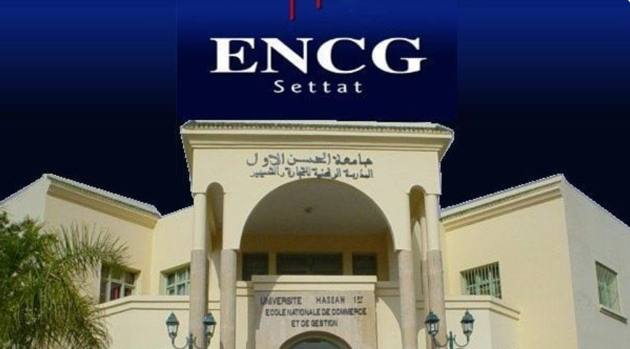

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [AIT BOUSALEM ISRAA] · **Code Apogée :** [23008729] · **Groupe :** [G1]  
**Sujet :** CI[101] — [Prévision des exportations marocaines] · **Date :** [19/11/2026]  
**Dépôt :** https://github.com/israaait/23008729-aitbousalem-CI

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


In [ ]:
import pandas as pd

chemin = '/content/drive/MyDrive/ds 2027/UNComtrade-trade-statistics-official-CAHS-20261119-1040.csv'

df = pd.read_csv(chemin, low_memory=False)

df.head()

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,2.381582e+10,2.381582e+10,0,True,False
1,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,1.770148e+06,1.770148e+06,0,True,False
2,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,2.102653e+08,2.102653e+08,0,True,False
3,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,7.592190e+05,7.592190e+05,0,True,False
4,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,8.242500e+07,8.242500e+07,0,True,False


# 1. Sujet et problématique

## Sujet : CI01 — Prévision des exportations marocaines

### Intérêt économique

Le commerce extérieur joue un rôle important dans le développement économique du Maroc. Les exportations permettent aux entreprises marocaines d'accéder à de nouveaux marchés, de générer des revenus en devises et de renforcer leur compétitivité internationale.

L'analyse des exportations par produit et par pays de destination permet de mieux comprendre les relations commerciales du Maroc avec ses partenaires étrangers. Elle aide également à identifier les évolutions de la demande internationale.

La prévision des exportations peut constituer un outil d'aide à la décision pour les entreprises et les organismes économiques. Elle permet d'anticiper les tendances commerciales et d'améliorer la planification des activités d'exportation.

### Problématique

Dans quelle mesure un modèle de Machine Learning peut-il prévoir la valeur des exportations marocaines selon les produits et les pays de destination à partir des données historiques ?

### Nature de la tâche

Régression supervisée.

### Objectif

Construire un modèle Ridge Regression capable de prévoir la valeur des exportations marocaines en utilisant les données historiques, puis comparer ses performances à une méthode de référence naïve.

### Métrique principale

L'erreur absolue moyenne (MAE), exprimée en dollars américains. L'objectif est de minimiser cette erreur sur les observations futures.

## 2. Jeu de données et dictionnaire des variables

**Source :** UN Comtrade (https://comtradeplus.un.org/ ; API/documentation : https://comtradeapi.un.org/). Fichier d’extraction fourni pour ce projet. Vérifier sur la plateforme la licence et la date exacte d’extraction, qui ne sont pas renseignées dans le fichier.

**Période :** 2014–2025, fréquence annuelle. **Déclarant :** Maroc (`MAR`). **Flux :** exportations (`X`). **Classification :** agrégat « All Commodities » (`TOTAL`), classification HS dont la version varie selon l’année (`H2`, `H4`, `H5`, `H6`). **Unité monétaire :** USD selon la convention UN Comtrade; valeurs nominales, non corrigées de l’inflation.

Une ligne représente une année et un partenaire commercial, après sélection du total douanier `C00`.

In [ ]:
# Chemin relatif conseillé pour le dépôt GitHub
CHEMIN_DONNEES = Path("data/raw/exportations_maroc_un_comtrade.txt")
if not CHEMIN_DONNEES.exists():
    # Fallback si le fichier conserve son nom initial dans le même dossier que le notebook
    candidats = [Path("Texte collé(3).txt"), Path("data/raw/Texte collé(3).txt")]
    CHEMIN_DONNEES = next((p for p in candidats if p.exists()), CHEMIN_DONNEES)
if not CHEMIN_DONNEES.exists():
    raise FileNotFoundError("Fichier introuvable. Placez l’extraction dans data/raw/ ou modifiez CHEMIN_DONNEES.")

df_brut = pd.read_csv(CHEMIN_DONNEES, sep="\t", low_memory=False)
print("Dimensions brutes :", df_brut.shape)
display(df_brut.head(3))
print("Années :", sorted(df_brut["refYear"].dropna().unique()))
print("Codes douaniers :")
display(df_brut.groupby(["refYear", "customsCode"]).size().rename("nombre_lignes").to_frame())

Dimensions brutes : (2485, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,2.381582e+10,2.381582e+10,0,True,False
1,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,1.770148e+06,1.770148e+06,0,True,False
2,C,A,20140101,2014,52,2014,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,2.102653e+08,2.102653e+08,0,True,False


Années : [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Codes douaniers :


,,nombre_lignes
refYear,customsCode,
2014,C00,172
2015,C00,174
2016,C00,180
2017,C00,178
2018,C00,180
2019,C00,183
2020,C00,177
2021,C00,172
2022,C00,178


In [ ]:
dictionnaire = pd.DataFrame([
    ["refYear", "Année de référence", "Entier / année", "Temps", "Année"],
    ["reporterISO", "Code du pays déclarant", "Texte", "Filtre", "MAR"],
    ["flowCode", "Code du flux commercial", "Texte", "Filtre", "X = Export"],
    ["partnerISO", "Code ISO du partenaire", "Texte", "Identifiant", "W00 = Monde"],
    ["partnerDesc", "Nom du partenaire", "Texte", "Description", "Nom du pays"],
    ["cmdCode", "Code produit agrégé", "Texte", "Filtre", "TOTAL = toutes marchandises"],
    ["customsCode", "Catégorie douanière", "Texte", "Filtre qualité", "C00 = total"],
    ["primaryValue", "Valeur commerciale principale", "Numérique / USD", "Variable analysée", "Valeur déclarée"],
    ["fobvalue", "Valeur FOB", "Numérique / USD", "Contrôle", "Valeur FOB"],
])
dictionnaire.columns = ["Variable", "Description", "Type / unité", "Rôle", "Valeur / remarque"]
display(dictionnaire)
print("Taux de valeurs manquantes (%) — variables principales")
display(df_brut[["refYear", "partnerISO", "partnerDesc", "primaryValue", "fobvalue"]].isna().mean().mul(100).rename("% manquants").to_frame())

,Variable,Description,Type / unité,Rôle,Valeur / remarque
0,refYear,Année de référence,Entier / année,Temps,Année
1,reporterISO,Code du pays déclarant,Texte,Filtre,MAR
2,flowCode,Code du flux commercial,Texte,Filtre,X = Export
3,partnerISO,Code ISO du partenaire,Texte,Identifiant,W00 = Monde
4,partnerDesc,Nom du partenaire,Texte,Description,Nom du pays
5,cmdCode,Code produit agrégé,Texte,Filtre,TOTAL = toutes marchandises
6,customsCode,Catégorie douanière,Texte,Filtre qualité,C00 = total
7,primaryValue,Valeur commerciale principale,Numérique / USD,Variable analysée,Valeur déclarée
8,fobvalue,Valeur FOB,Numérique / USD,Contrôle,Valeur FOB


Taux de valeurs manquantes (%) — variables principales


,% manquants
refYear,0.0
partnerISO,0.0
partnerDesc,0.0
primaryValue,0.0
fobvalue,0.0


## 3. Exploration et trois figures interprétées
Construisez **trois graphiques en couleurs** (titre, axes, unités) et commentez chacun en 2 à 4 lignes. Vérifiez en particulier les doublons *pays–partenaire–produit–période*, les unités et les valeurs manquantes.

**Figure 1 — Interprétation :** [À COMPLÉTER]

**Figure 2 — Interprétation :** [À COMPLÉTER]

**Figure 3 — Interprétation :** [À COMPLÉTER]

In [ ]:
# Filtres cohérents : Maroc, exportations, toutes marchandises, total douanier C00
df = df_brut[(df_brut["reporterISO"] == "MAR") &
            (df_brut["flowCode"] == "X") &
            (df_brut["cmdCode"] == "TOTAL") &
            (df_brut["customsCode"] == "C00")].copy()
df["refYear"] = pd.to_numeric(df["refYear"], errors="coerce").astype("Int64")
df["primaryValue"] = pd.to_numeric(df["primaryValue"], errors="coerce")
df = df.dropna(subset=["refYear", "partnerISO", "primaryValue"])
print("Après filtre C00 :", df.shape)
print("Doublons année-partenaire :", df.duplicated(["refYear", "partnerISO"]).sum())
assert df.duplicated(["refYear", "partnerISO"]).sum() == 0, "Des doublons année-partenaire subsistent."

monde = df[df["partnerISO"] == "W00"].copy()
partenaires = df[df["partnerISO"] != "W00"].copy()
print("Nombre d'années :", df["refYear"].nunique(), "| partenaires distincts :", partenaires["partnerISO"].nunique())
print("Valeurs négatives :", int((df["primaryValue"] < 0).sum()))
display(df.groupby("refYear").agg(lignes=("partnerISO","size"), partenaires=("partnerISO","nunique"), valeur_moyenne=("primaryValue","mean")).round(2))

Après filtre C00 : (2145, 47)
Doublons année-partenaire : 0
Nombre d'années : 12 | partenaires distincts : 207
Valeurs négatives : 0


,lignes,partenaires,valeur_moyenne
refYear,,,
2014,172,172,2.769281e+08
2015,174,174,2.567464e+08
2016,180,180,2.539810e+08
2017,178,178,2.879135e+08
2018,180,180,3.260619e+08
2019,183,183,3.233049e+08
2020,177,177,3.130251e+08
2021,172,172,4.254096e+08
2022,178,178,4.739716e+08


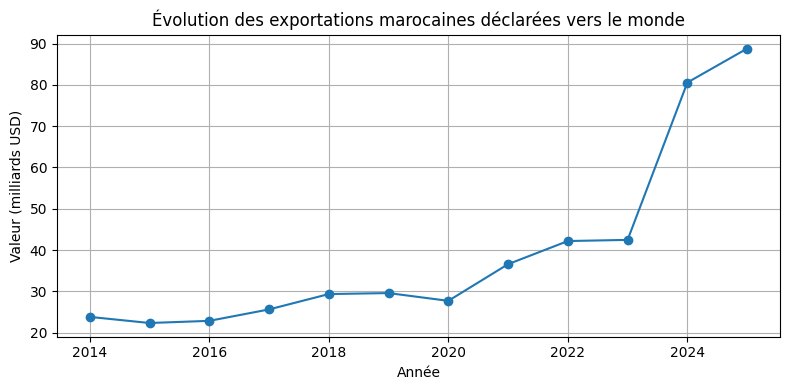

Interprétation automatique : le total World varie de 22.34 à 88.79 milliards USD sur la période. Vérifier les ruptures et la comparabilité des années avant toute explication causale.


In [ ]:
# Figure 1 : total déclaré pour le partenaire World
serie_monde = monde.groupby("refYear")["primaryValue"].sum().sort_index()
fig, ax = plt.subplots()
ax.plot(serie_monde.index.astype(int), serie_monde.values / 1e9, marker="o", color="#1f77b4")
ax.set(title="Évolution des exportations marocaines déclarées vers le monde", xlabel="Année", ylabel="Valeur (milliards USD)")
plt.tight_layout(); plt.show()
print("Interprétation automatique : le total World varie de", round(serie_monde.min()/1e9,2), "à", round(serie_monde.max()/1e9,2), "milliards USD sur la période. Vérifier les ruptures et la comparabilité des années avant toute explication causale.")

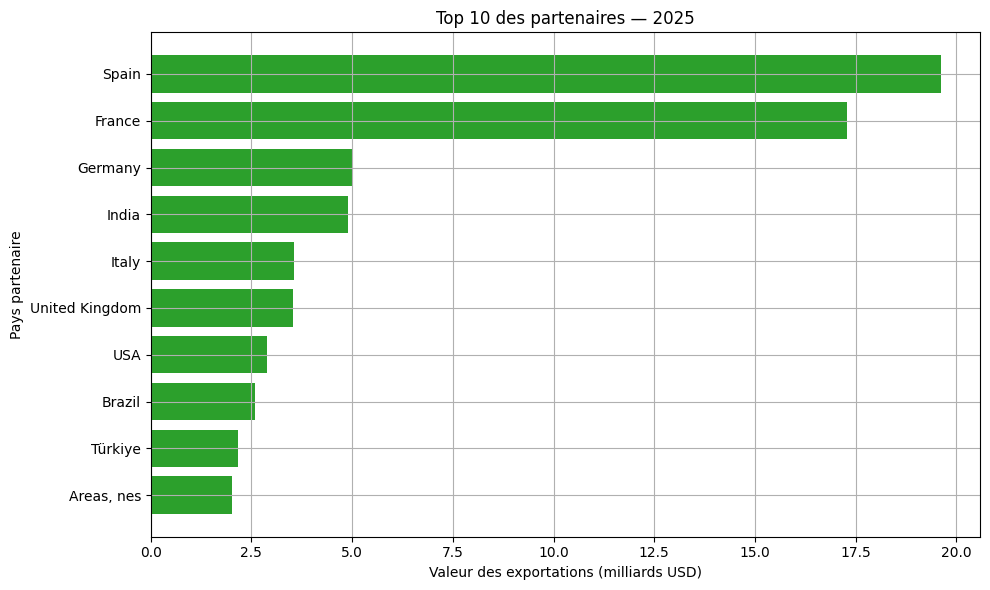

Les partenaires affichés sont les dix destinations présentant les valeurs les plus élevées dans l'année 2025 .


In [ ]:
# Figure 2 : principaux partenaires sur la dernière année disponible dans C00
derniere_annee = int(partenaires["refYear"].max())
top = (partenaires[partenaires["refYear"] == derniere_annee]
       .groupby("partnerDesc")["primaryValue"].sum().nlargest(10).sort_values())
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(top.index, top.values / 1e9, color="#2ca02c")
ax.set(title=f"Top 10 des partenaires — {derniere_annee}", xlabel="Valeur des exportations (milliards USD)", ylabel="Pays partenaire")
plt.tight_layout(); plt.show()
print("Les partenaires affichés sont les dix destinations présentant les valeurs les plus élevées dans l'année", derniere_annee, ".")

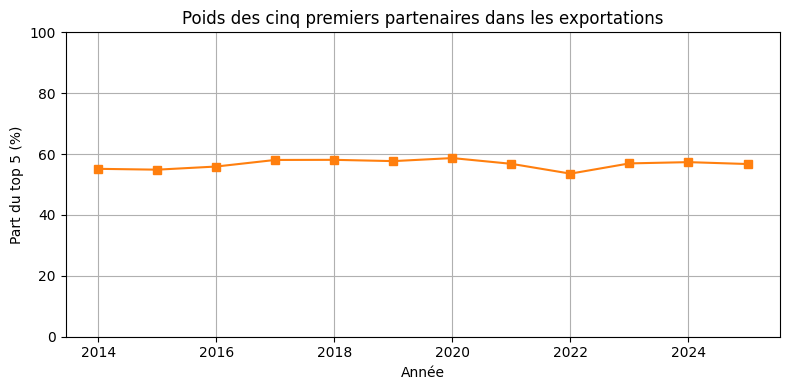

La part du top 5 mesure la concentration des exportations entre les principaux partenaires. Une baisse indique une répartition plus diffuse, sans suffire à elle seule à prouver une diversification durable.


In [ ]:
# Figure 3 : concentration des exportations dans le top 5 partenaires par année
concentration = []
for annee, g in partenaires.groupby("refYear"):
    total = g["primaryValue"].sum()
    top5 = g["primaryValue"].nlargest(5).sum()
    concentration.append({"Année": int(annee), "Part_top5_pct": (top5 / total * 100) if total else np.nan})
conc = pd.DataFrame(concentration).sort_values("Année")
fig, ax = plt.subplots()
ax.plot(conc["Année"], conc["Part_top5_pct"], marker="s", color="#ff7f0e")
ax.set(title="Poids des cinq premiers partenaires dans les exportations", xlabel="Année", ylabel="Part du top 5 (%)", ylim=(0,100))
plt.tight_layout(); plt.show()
print("La part du top 5 mesure la concentration des exportations entre les principaux partenaires. Une baisse indique une répartition plus diffuse, sans suffire à elle seule à prouver une diversification durable.")

## 4. Préparation et découpage sans fuite
**Traitements réalisés :** [IMPUTATION, DOUBLONS, CONVERSION DES UNITÉS, VARIABLES]

**Stratégie de découpage :** [DATES SI TEMPORALITÉ / STRATIFICATION SI CLASSIFICATION]

**Contrôle de fuite :** transformations `fit` sur le train uniquement et test réservé à la fin.

Pour les projets **non supervisés ou transversaux**, décrire un protocole de stabilité / de robustesse adapté, plutôt que de forcer une cible artificielle.

In [ ]:
# Matrice pays x années ; les absences de lignes sont interprétées comme absence de valeur enregistrée,
# et remplacées par 0 uniquement pour construire le profil temporel. Cette hypothèse doit être discutée.
pivot = partenaires.pivot_table(index=["partnerISO", "partnerDesc"], columns="refYear", values="primaryValue", aggfunc="sum", fill_value=0)
pivot.columns = [int(c) for c in pivot.columns]
# Exclure les partenaires sans aucune valeur positive sur toute la période
pivot = pivot.loc[pivot.sum(axis=1) > 0].copy()

profils = pd.DataFrame(index=pivot.index)
profils["moyenne_annuelle_usd"] = pivot.mean(axis=1)
profils["mediane_annuelle_usd"] = pivot.median(axis=1)
profils["ecart_type_usd"] = pivot.std(axis=1)
profils["annees_avec_export"] = (pivot > 0).sum(axis=1)
annees = sorted(pivot.columns)
profils["moyenne_3_dernieres_annees_usd"] = pivot[annees[-3:]].mean(axis=1)
profils = profils.replace([np.inf, -np.inf], np.nan).dropna()
X_log = np.log1p(profils[["moyenne_annuelle_usd", "mediane_annuelle_usd", "ecart_type_usd", "moyenne_3_dernieres_annees_usd"]].clip(lower=0))

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print("Nombre de partenaires retenus :", len(profils))
display(profils.describe().T)

Nombre de partenaires retenus : 207


,count,mean,std,min,25%,50%,75%,max
moyenne_annuelle_usd,207.0,1.899594e+08,8.640333e+08,2.456917,443538.162042,8.821901e+06,8.302926e+07,8.821568e+09
mediane_annuelle_usd,207.0,1.448958e+08,6.841142e+08,0.000000,76872.265750,4.991542e+06,6.625173e+07,7.032493e+09
ecart_type_usd,207.0,1.181003e+08,4.823506e+08,8.511009,518842.640364,7.678928e+06,4.781073e+07,4.904923e+09
annees_avec_export,207.0,1.030435e+01,3.306236e+00,1.000000,10.000000,1.200000e+01,1.200000e+01,1.200000e+01
moyenne_3_dernieres_annees_usd,207.0,3.411020e+08,1.539217e+09,0.000000,336799.897333,1.223134e+07,1.267724e+08,1.579533e+10


## 5. Algorithme principal : K-means (à confirmer avec la liste des 29 algorithmes du cours)

**Pourquoi K-means ?** Il regroupe les partenaires selon la proximité de leurs profils numériques et produit des groupes faciles à décrire pour une lecture commerciale. La transformation logarithmique limite l’influence des valeurs extrêmes et la standardisation évite qu’une variable domine uniquement par son unité. Une alternative plausible serait le clustering hiérarchique, qui permettrait d’observer les rapprochements entre marchés sans imposer la même logique de centroïdes. K-means reste simple à interpréter et à reproduire.

**Fonction objectif :** minimiser la somme des distances quadratiques intra-groupes :

\[ J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2 \]

`K` est le nombre de groupes, `C_k` le groupe k, `x_i` le vecteur standardisé du partenaire i, et `μ_k` le centroïde du groupe k. Les paramètres appris sont les centroïdes et l’affectation des observations. Hyperparamètres étudiés : nombre de clusters `K` et nombre d’initialisations `n_init`.

,K,inertie,silhouette
0,2,306.494084,0.574751
1,3,177.547120,0.512174
2,4,127.029344,0.459773
3,5,104.064073,0.453370
4,6,85.916455,0.418010


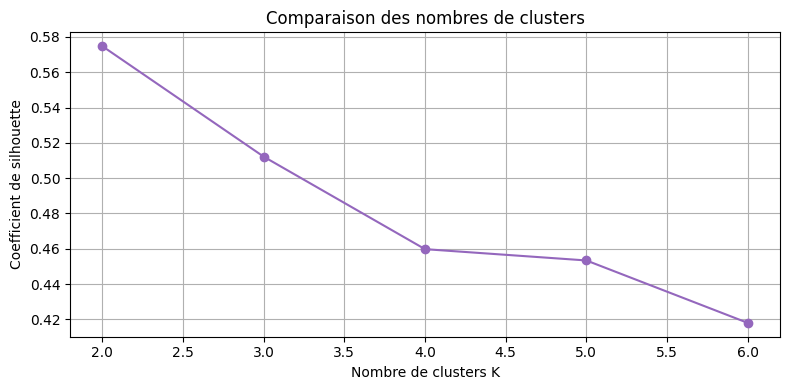

K retenu selon la silhouette maximale : 2
Silhouette du modèle retenu : 0.5748


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Recherche exploratoire de K ; silhouette définie si au moins deux groupes et moins de groupes que d'observations
resultats_k = []
for k in range(2, min(7, len(profils))):
    modele_k = KMeans(n_clusters=k, random_state=GRAINE, n_init=20, max_iter=300)
    labels_k = modele_k.fit_predict(X_scaled)
    resultats_k.append({"K": k, "inertie": modele_k.inertia_, "silhouette": silhouette_score(X_scaled, labels_k)})
eval_k = pd.DataFrame(resultats_k)
display(eval_k)

fig, ax = plt.subplots()
ax.plot(eval_k["K"], eval_k["silhouette"], marker="o", color="#9467bd")
ax.set(title="Comparaison des nombres de clusters", xlabel="Nombre de clusters K", ylabel="Coefficient de silhouette")
plt.tight_layout(); plt.show()
K_RETENU = int(eval_k.loc[eval_k["silhouette"].idxmax(), "K"])
print("K retenu selon la silhouette maximale :", K_RETENU)
modele = KMeans(n_clusters=K_RETENU, random_state=GRAINE, n_init=20, max_iter=300)
profils["cluster"] = modele.fit_predict(X_scaled)
print("Silhouette du modèle retenu :", round(silhouette_score(X_scaled, profils["cluster"]), 4))

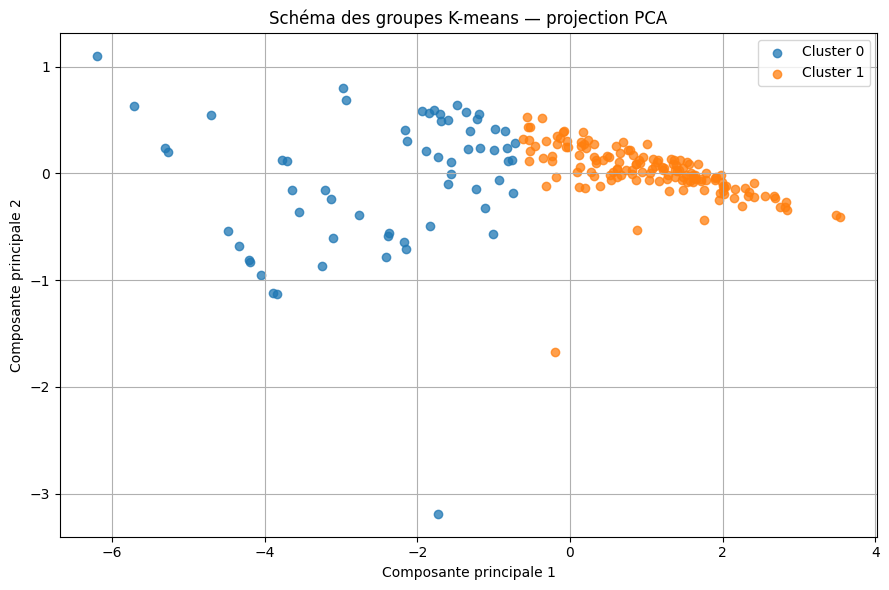

La PCA projette les profils en deux dimensions pour faciliter la lecture ; le clustering a été ajusté sur les variables standardisées complètes.


In [ ]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

# Projection 2D pour visualiser les groupes (PCA utilisée uniquement pour la visualisation)
pca = PCA(n_components=2, random_state=GRAINE)
coords = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(9,6))
for cl in sorted(profils["cluster"].unique()):
    masque = profils["cluster"].to_numpy() == cl
    ax.scatter(coords[masque,0], coords[masque,1], label=f"Cluster {cl}", alpha=.75)
ax.set(title="Schéma des groupes K-means — projection PCA", xlabel="Composante principale 1", ylabel="Composante principale 2")
ax.legend(); plt.tight_layout(); plt.show()
print("La PCA projette les profils en deux dimensions pour faciliter la lecture ; le clustering a été ajusté sur les variables standardisées complètes.")

## 6. Protocole expérimental

**Référence descriptive :** classement des partenaires par moyenne annuelle, sans apprentissage. K-means est comparé à cette lecture par sa capacité à révéler plusieurs profils plutôt qu’un simple ordre.

**Validation :** comparaison des valeurs de K entre 2 et 6 avec le coefficient de silhouette; choix du K présentant la silhouette la plus élevée parmi les candidats testés. Les données ne sont pas utilisées comme un jeu supervisé et aucun score de prédiction n’est revendiqué. Une analyse de stabilité par plusieurs graines est ajoutée ci-dessous.

In [ ]:
# Profils moyens par cluster, en unités originales
resume_clusters = profils.groupby("cluster").agg(
    nombre_pays=("moyenne_annuelle_usd", "size"),
    moyenne_annuelle_usd=("moyenne_annuelle_usd", "mean"),
    mediane_annuelle_usd=("mediane_annuelle_usd", "median"),
    annees_moyennes_avec_export=("annees_avec_export", "mean"),
    moyenne_3_dernieres_annees_usd=("moyenne_3_dernieres_annees_usd", "mean")
).sort_values("moyenne_annuelle_usd", ascending=False)
display(resume_clusters.style.format({c:"{:,.0f}" for c in resume_clusters.select_dtypes(include="number").columns if c != "nombre_pays"}))

# Principaux partenaires de chaque cluster
profils_affichage = profils.reset_index()
for cl in sorted(profils["cluster"].unique()):
    print(f"\nCluster {cl} — principaux partenaires :")
    display(profils_affichage[profils_affichage["cluster"] == cl].nlargest(10, "moyenne_annuelle_usd")[["partnerDesc", "moyenne_annuelle_usd", "moyenne_3_dernieres_annees_usd", "annees_avec_export"]])

,nombre_pays,moyenne_annuelle_usd,mediane_annuelle_usd,annees_moyennes_avec_export,moyenne_3_dernieres_annees_usd
cluster,,,,,
1,145,"270,874,732","26,227,386",12,"486,861,871"
0,62,"721,863","2,101",7,"212,130"



Cluster 0 — principaux partenaires :


,partnerDesc,moyenne_annuelle_usd,moyenne_3_dernieres_annees_usd,annees_avec_export
201,Bunkers,3.509358e+07,0.000000e+00,1
135,Nicaragua,8.690113e+05,1.341515e+05,9
99,Cambodia,8.347309e+05,2.059345e+05,12
12,Azerbaijan,6.240652e+05,1.862681e+05,12
88,Iran,5.400703e+05,8.998690e+03,12
8,Armenia,5.325382e+05,1.130478e+06,10
68,Gibraltar,4.937537e+05,1.359617e+05,12
193,Uzbekistan,4.862220e+05,1.831778e+06,9
93,Jamaica,4.690134e+05,1.345221e+06,10
5,Andorra,4.496405e+05,1.804528e+05,11



Cluster 1 — principaux partenaires :


,partnerDesc,moyenne_annuelle_usd,moyenne_3_dernieres_annees_usd,annees_avec_export
57,Spain,8.821568e+09,1.579533e+10,12
63,France,8.047522e+09,1.394065e+10,12
92,Italy,1.793751e+09,3.333210e+09,12
85,India,1.635254e+09,2.939774e+09,12
48,Germany,1.583819e+09,3.741677e+09,12
65,United Kingdom,1.375076e+09,2.989358e+09,12
26,Brazil,1.338703e+09,2.143510e+09,12
192,USA,1.337775e+09,2.186173e+09,12
187,Türkiye,9.892149e+08,1.810360e+09,12
136,Netherlands,8.497301e+08,1.216992e+09,12


In [ ]:
# Profils moyens par cluster, en unités originales
resume_clusters = profils.groupby("cluster").agg(
    nombre_pays=("moyenne_annuelle_usd", "size"),
    moyenne_annuelle_usd=("moyenne_annuelle_usd", "mean"),
    mediane_annuelle_usd=("mediane_annuelle_usd", "median"),
    annees_moyennes_avec_export=("annees_avec_export", "mean"),
    moyenne_3_dernieres_annees_usd=("moyenne_3_dernieres_annees_usd", "mean")
).sort_values("moyenne_annuelle_usd", ascending=False)
display(resume_clusters.style.format({c:"{:,.0f}" for c in resume_clusters.select_dtypes(include="number").columns if c != "nombre_pays"}))

# Principaux partenaires de chaque cluster
profils_affichage = profils.reset_index()
for cl in sorted(profils["cluster"].unique()):
    print(f"\nCluster {cl} — principaux partenaires :")
    display(profils_affichage[profils_affichage["cluster"] == cl].nlargest(10, "moyenne_annuelle_usd")[["partnerDesc", "moyenne_annuelle_usd", "moyenne_3_dernieres_annees_usd", "annees_avec_export"]])

,nombre_pays,moyenne_annuelle_usd,mediane_annuelle_usd,annees_moyennes_avec_export,moyenne_3_dernieres_annees_usd
cluster,,,,,
1,145,"270,874,732","26,227,386",12,"486,861,871"
0,62,"721,863","2,101",7,"212,130"



Cluster 0 — principaux partenaires :


,partnerDesc,moyenne_annuelle_usd,moyenne_3_dernieres_annees_usd,annees_avec_export
201,Bunkers,3.509358e+07,0.000000e+00,1
135,Nicaragua,8.690113e+05,1.341515e+05,9
99,Cambodia,8.347309e+05,2.059345e+05,12
12,Azerbaijan,6.240652e+05,1.862681e+05,12
88,Iran,5.400703e+05,8.998690e+03,12
8,Armenia,5.325382e+05,1.130478e+06,10
68,Gibraltar,4.937537e+05,1.359617e+05,12
193,Uzbekistan,4.862220e+05,1.831778e+06,9
93,Jamaica,4.690134e+05,1.345221e+06,10
5,Andorra,4.496405e+05,1.804528e+05,11



Cluster 1 — principaux partenaires :


,partnerDesc,moyenne_annuelle_usd,moyenne_3_dernieres_annees_usd,annees_avec_export
57,Spain,8.821568e+09,1.579533e+10,12
63,France,8.047522e+09,1.394065e+10,12
92,Italy,1.793751e+09,3.333210e+09,12
85,India,1.635254e+09,2.939774e+09,12
48,Germany,1.583819e+09,3.741677e+09,12
65,United Kingdom,1.375076e+09,2.989358e+09,12
26,Brazil,1.338703e+09,2.143510e+09,12
192,USA,1.337775e+09,2.186173e+09,12
187,Türkiye,9.892149e+08,1.810360e+09,12
136,Netherlands,8.497301e+08,1.216992e+09,12


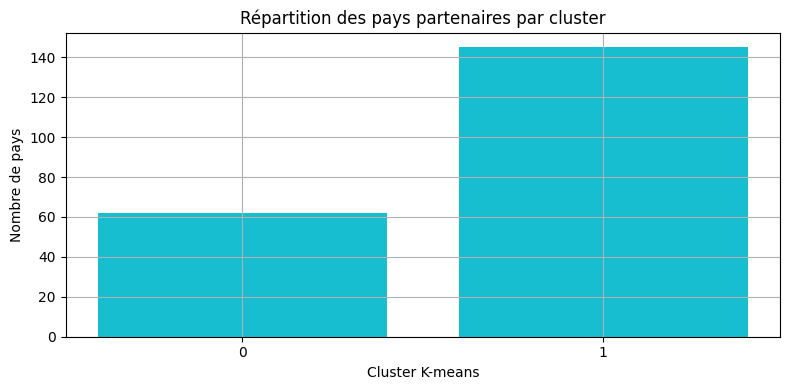

,Méthode,Validation,Test final,Indicateur
0,Classement descriptif,Sans score prédictif,Non applicable,Rang par moyenne annuelle
1,K-means,Silhouette=0.5748,Non applicable (non supervisé),K=2; inertie=306.49


In [ ]:
# Figure résultats : nombre de pays par cluster
counts = profils["cluster"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values, color="#17becf")
ax.set(title="Répartition des pays partenaires par cluster", xlabel="Cluster K-means", ylabel="Nombre de pays")
plt.tight_layout(); plt.show()

resultats = pd.DataFrame([
    {"Méthode": "Classement descriptif", "Validation": "Sans score prédictif", "Test final": "Non applicable", "Indicateur": "Rang par moyenne annuelle"},
    {"Méthode": "K-means", "Validation": f"Silhouette={silhouette_score(X_scaled, profils['cluster']):.4f}", "Test final": "Non applicable (non supervisé)", "Indicateur": f"K={K_RETENU}; inertie={modele.inertia_:.2f}"}
])
display(resultats)

## 8. Analyse critique

**Limites des données :** les valeurs sont nominales et peuvent refléter à la fois les volumes et les prix. Le fichier est agrégé à « toutes marchandises » : il ne permet pas d’identifier les secteurs ou produits qui expliquent les échanges. La classification HS change au fil des années. Les données de 2025 peuvent être provisoires selon la date d’extraction. La présence d’une valeur nulle ou l’absence d’une ligne ne signifie pas nécessairement absence totale de relation commerciale.

**Limites méthodologiques :** K-means suppose des groupes relativement compacts et dépend de l’échelle des variables et de l’initialisation. Le choix du nombre de clusters par silhouette n’est pas une vérité économique. La transformation logarithmique et le remplacement des absences par zéro influencent les profils. Les montants ne sont pas corrigés de l’inflation ni convertis en indicateurs par habitant ou par taille de marché.

**Améliorations :** (1) compléter avec des données par produit/chapitre SH pour distinguer diversification géographique et sectorielle; (2) enrichir avec PIB, population, distance, accords commerciaux et données d’importations des partenaires, puis tester une segmentation hiérarchique et une analyse de sensibilité des valeurs manquantes.

## 9. Conclusion
**Réponse explicite à la problématique :** [3–5 lignes]

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** [À COMPLÉTER]

In [ ]:
# Synthèse automatique de quelques indicateurs observés
print("Période étudiée :", int(partenaires.refYear.min()), "à", int(partenaires.refYear.max()))
print("Nombre de partenaires distincts :", partenaires.partnerISO.nunique())
print("Part top 5 — première année (%):", round(conc.iloc[0]["Part_top5_pct"], 2))
print("Part top 5 — dernière année (%):", round(conc.iloc[-1]["Part_top5_pct"], 2))
print("Nombre de clusters retenu :", K_RETENU)
print("Silhouette :", round(silhouette_score(X_scaled, profils.cluster), 4))
print("À partir de ces sorties, rédiger une conclusion commerciale nuancée.")

Période étudiée : 2014 à 2025
Nombre de partenaires distincts : 207
Part top 5 — première année (%): 55.16
Part top 5 — dernière année (%): 56.74
Nombre de clusters retenu : 2
Silhouette : 0.5748
À partir de ces sorties, rédiger une conclusion commerciale nuancée.


## 10. Références, reproduction et dépôt
- **Données :** [URL, licence, date]
- **Documentation scientifique et technique :** [LIENS]
- **GitHub :** [LIEN]
- **Réexécution :** `pip install -r requirements.txt` ; exécuter les cellules dans l'ordre.

## Déclaration obligatoire de l'usage de l'IA
| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
| [Aucun / outil et version] | [usage exact] | [...] | [...] |

## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7